# H1: styl życia a wiek i zainteresowania w predykcji prawego swipe'a

**Wersja po audycie 2026-11-08** (gałąź `fix/h1-audit`). Zmiany względem poprzedniej wersji, liczby przed/po i oznaczenie
„pre-rejestrowana / post hoc” są w `docs/h1/audit-fixes-2026-11-08.md`; otwarte decyzje w `docs/h1/open-questions.md`.

## O co pytamy (po ludzku)

W aplikacji osoba **A** przegląda profil osoby **B** i przesuwa go w prawo (zainteresowana) albo w lewo (nie).
Hipoteza **H1** pyta: **czy zgodność stylu życia przewiduje prawy swipe silniej niż zgodność wieku i zainteresowań?**
Badamy **prawy swipe w aplikacji**, a nie faktyczny najem (D1); język jest ostrożny: „jest związane z”, „przewiduje”.

## Kryterium z karty M1 (sekcja 4, H1)

H1 jest potwierdzona, jeśli przyrost jakości dopasowania po dodaniu stylu życia jest **większy** niż po dodaniu wieku i zainteresowań,
a **przedział ufności różnicy nie obejmuje zera**. Wynik negatywny jest pełnoprawnym wynikiem. W tym notebooku to kryterium
sprawdzamy bezpośrednio: bootstrap klastrowany po nadawcach i po odbiorcach (szerszy z przedziałów = konserwatywny), obie kolejności
włączania bloków oraz walidacja krzyżowa po nadawcach ze sparowanymi różnicami.

## Jednostka, zmienna wynikowa, estymator

Jeden wiersz = jeden skierowany swipe A→B na profil; `y_right` = 1 dla prawego swipe'a. Regresja logistyczna; błędy standardowe
w modelu pełnym klastrowane dwustronnie (nadawca, odbiorca; **D18**). Log-wiarygodność nie zależy od estymatora wariancji, ale
**zakłada niezależne obserwacje**, więc same wartości ΔLL zawyżają siłę dowodu; dlatego o kryterium rozstrzygają przedziały z bootstrapu klastrowego.

## Specyfikacja po audycie

- **Kontrole identyczne we wszystkich modelach (Z1):** 8 dummies `sex_pair` (nadawca→odbiorca, referencja F→F; Z2) oraz `city_same`, `city_diff`.
- **Blok wieku (Z3):** `same_band`, `age_band_diff_abs` (odległość), `age_band_diff` (kierunek: odbiorca − nadawca). Wariant z `|diff|²` i z efektami stałymi pasma nadawcy w analizie wrażliwości.
- **Blok zainteresowań:** `interests_jaccard`, `interests_shared_n`, `interests_count_diff_abs`. Wariant z IDF-Jaccardem i z kontrolą sufitu 9 tagów (Z6).
- **Blok stylu życia:** `lifestyle_agree_ratio`, `lifestyle_tag_conflict`, `lifestyle_shared_tags_n` (+ analiza per pole, Z7).
- Wszystkie modele liczone na **tej samej próbie kompletnych przypadków** (n podany w lejku, Z8).

## Decyzje zespołu zastosowane tutaj

(`docs/prompts/m1-generation-plan.md`, `docs/codebook.md`): cechy z wersji profilu z dnia swipe'a (**D7**), bez Hyderabadu (**D10**),
płeć `O` osobno (**D8**), pasma 27+ połączone (**D9**), bez wykluczania kont skrajnych w analizie głównej (**D6**),
tagi stylu życia uzupełniają braki pól strukturalnych (**D12, D13**), obie kolejności włączania bloków (**D16**), foldy po użytkownikach (**D18**).

## Prywatność (G12)

Żadne pola `bio` nie są wczytywane. Do raportu trafiają wyłącznie agregaty; komórki z mniej niż 5 użytkownikami są tłumione.
Zbiór analityczny zawiera zbiory kanonicznych tagów hobby (kategorie, nie tekst użytkownika) i jest poza gitem.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from rentfriends import h1, h1_audit
from rentfriends.dataset_h1 import load_user_idf, weighted_jaccard

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", lambda v: f"{v:.4f}")

SEED = 42  # stałe ziarno: bootstrap, permutacje, foldy CV
N_BOOT = 1000  # bootstrap klastrowy (>= 500 wg zadania)
N_BOOT_CV = 500
N_PERM = 500
N_FOLDS = 5

PURPLE, PURPLE_INK, BLUE, GRAY, HAIR, CORAL = (
    "#A247E3",
    "#8B34C4",
    "#234CE0",
    "#595959",
    "#D5D2CB",
    "#D9534F",
)

DATA_DIR = Path("../data/processed")

## 1. Wczytanie danych

Zbiór `h1_analysis_dataset.parquet` (cechy as-of wg **D7**, bez Hyderabadu **D10**, tagi oczyszczone wg **D12/D13**).
Schemat był rozszerzany wstecznie zgodnie: dodano kolumny (IDF-Jaccard, sufit tagów, status pól stylu życia), nic nie usunięto.

In [2]:
df = h1.load_h1_data(DATA_DIR)
print(f"Wczytano {df.shape[0]:,} obserwacji, {df.shape[1]} kolumn.")

# Kontrole prywatności i filtrów
assert not any("bio" in c.lower() for c in df.columns), "wykryto kolumny bio!"
users_raw = pd.read_parquet(DATA_DIR / "users.parquet", columns=["user_key", "city"])
hyd_users = set(users_raw.loc[users_raw["city"] == "Hyderabad", "user_key"])
assert not (df["user_key"].isin(hyd_users) | df["target_user_key"].isin(hyd_users)).any()
print("OK: brak kolumn bio, brak kont z Hyderabadu.")

Wczytano 94,295 obserwacji, 51 kolumn.
OK: brak kolumn bio, brak kont z Hyderabadu.


## Słownik zmiennych (zbiór danych H1)

Poniższe zestawienie wyjaśnia znaczenie operacyjne oraz sens istnienia w badaniu każdej z kolumn analitycznych przygotowanych w zbiorze `h1_analysis_dataset.parquet` 

### 1. Rekonstrukcja profilu as-of w czasie i analiza wrażliwości (D7, D6)
- **`source_flag_receiver`** (kategorie: `prior_version`, `first_version`, `users_current`): Źródło cech profilu odbiorcy. Wskazuje, czy profil pochodzi ściśle z wersji sprzed dnia decyzji (`prior_version` — brak wycieku danych z przyszłości), z pierwszej zarejestrowanej wersji (`first_version`), czy z tabeli bieżącej (`users_current`). Umożliwia weryfikację odporności (**D7**).
- **`source_flag_sender`** (kategorie: `prior_version`, `first_version`, `users_current`): Analogiczna flaga źródła profilu dla nadawcy swipe'a (**D7**).
- **`both_prior_version`** (0/1): Binarna flaga oznaczająca, że cechy profilu **obu** stron pochodzą ściśle ze stanu sprzed dnia decyzji. Służy jako filtr w najbardziej restrykcyjnym scenariuszu analizy wrażliwości (**D7**).
- **`sender_total_swipes`** (int): Łączna liczba swipe'ów wykonanych przez danego nadawcę. Pozwala kontrolować intensywność korzystania z aplikacji.
- **`sender_right_rate`** (float $[0, 1]$): Odsetek prawych swipe'ów nadawcy. Mierzy indywidualny poziom selektywności użytkownika (od osób bardzo wybrednych po klikające bez selekcji).
- **`is_low_activity`** (0/1): Flaga użytkownika o małej aktywności ($< 10$ swipe'ów). Służy w analizie wrażliwości (**D6**) do weryfikacji, czy incydentalni użytkownicy nie zniekształcają wyników.
- **`is_extreme_user`** (0/1): Flaga użytkownika o skrajnym zachowaniu ($0\%$ lub $100\%$ prawych swipe'ów — potencjalne boty lub użytkownicy nieselektywni). Używana do testu odporności w analizie wrażliwości (**D6**).

### 2. Kontrola demograficzna: Płeć (D8)
- **`sex_sender`** (kategorie: `F`, `M`, `O`): Płeć nadawcy swipe'a (zgodnie z **D8** płeć `O` stanowi odrębną kategorię). Podstawowa zmienna demograficzna.
- **`sex_receiver`** (kategorie: `F`, `M`, `O`): Płeć odbiorcy swipe'a.
- **`same_sex`** (0/1): Flaga tej samej płci nadawcy i odbiorcy. Kluczowa zmienna zakłócająca — preferencje dotyczące płci współlokatora (np. kobiety poszukujące wyłącznie współlokatorek) są jednym z najsilniejszych filtrów wstępnych na rynku najmu.
- **`sex_pair`** (kategorie: np. `F-F`, `M-M`, `F-M`, `M-F` itp.): Kategoryczny typ relacji płciowej w parze. Pozwala na pełną kontrolę interakcji płciowych w eksploracji i tabelach krzyżowych.

### 3. Blok Wieku (konkurencyjny wymiar demograficzny, D9)
- **`age_band_sender`** (kategorie: `18-20`, `21-23`, `24-26`, `27+`): Pasmo wieku nadawcy (po złączeniu pasm $27+$ wg **D9**).
- **`age_band_receiver`** (kategorie): Pasmo wieku odbiorcy (po złączeniu pasm $27+$ wg **D9**).
- **`same_band`** (0/1): Flaga tożsamości pasma wieku obu użytkowników. Podstawowa miara homofilii wiekowej — testuje, czy użytkownicy preferują osoby na dokładnie tym samym etapie życia.
- **`age_band_diff`** (int): Kierunkowa różnica rang pasm wieku ($\text{odbiorca} - \text{nadawca}$). To jest **kierunek, nie podobieństwo wieku**: wartość 0 oznacza to samo pasmo, a znak mówi tylko, czy odbiorca jest starszy czy młodszy. Nadawca z pasma 18-20 nie może mieć wartości ujemnych (65% profili to 18-20).
- **`age_band_diff_abs`** (int): Bezwzględna różnica rang pasm wieku ($|\text{diff}|$). Mierzy odległość pokoleniową między użytkownikami niezależnie od kierunku.

### 4. Kontrola geograficzna: Miasto (D10)
- **`city_sender`** (str): Miasto zadeklarowane przez nadawcę (po wykluczeniu kont z Hyderabadu wg **D10**).
- **`city_receiver`** (str): Miasto zadeklarowane przez odbiorcę (po wykluczeniu kont z Hyderabadu wg **D10**).
- **`same_city`** (kategorie: `same`, `different`, `unknown`): Kategoryczna zgodność lokalizacji nadawcy i odbiorcy.
- **`city_same`** (0/1): Binarna zmienna dummy oznaczająca, że nadawca i odbiorca deklarują to samo znane miasto. Używana w regresji logistycznej do wychwycenia premii za wspólne miasto.
- **`city_diff`** (0/1): Binarna zmienna dummy oznaczająca, że nadawca i odbiorca deklarują różne znane miasta. Używana w regresji logistycznej do kontroli kosztu poszukiwania lokalu w innym mieście.

### 5. Blok Stylu Życia (główny badany wymiar hipotezy H1, D12, D13)
- **`lifestyle_agreed_count`** (int): Liczba cech stylu życia, w których obie strony mają identyczną deklarację (po uzupełnieniu braków tagami wg **D13**). Licznik zgodności nawyków (czystość, hałas, palenie, alkohol, rytm dnia, praca zdalna).
- **`lifestyle_known_count`** (int): Liczba cech stylu życia zadeklarowanych przez obie osoby. Stanowi mianownik wskaźnika zgodności i zabezpiecza przed zniekształceniem estymacji przez brak danych.
- **`lifestyle_agree_ratio`** (float $[0, 1]$): Syntetyczny wskaźnik zgodności codziennych nawyków ($\frac{\text{lifestyle\_agreed\_count}}{\text{lifestyle\_known\_count}}$). Główny skalar mierzący kompatybilność współlokatorską w hipotezie H1.
- **`lifestyle_shared_tags_n`** (int): Liczba wspólnych tagów tożsamościowych związanych ze stylem życia. Mierzy afirmatywne podobieństwo deklaracji.
- **`lifestyle_tag_conflict`** (0/1): Binarna flaga bezpośredniego konfliktu kierunkowego na kluczowych nawykach (np. palący vs niepalący, głośny vs cichy, ranny ptaszek vs nocny marek). W odróżnieniu od ogólnej zgodności wychwytuje tzw. *deal-breakery*, które mogą natychmiastowo dyskwalifikować drugą osobę.

### 6. Blok Zainteresowań i Hobby (konkurencyjny wymiar behawioralny, D12, D13)
- **`interests_jaccard`** (float $[0, 1]$): Indeks podobieństwa Jaccarda ($\frac{|A \cap B|}{|A \cup B|}$) liczony wyłącznie na czystych zainteresowaniach (po usunięciu tagów stylu życia wg **D12/D13**). Główny znormalizowany wskaźnik zbieżności pasji i tematów do rozmowy w konkurencyjnym bloku H1.
- **`interests_shared_n`** (int): Bezwzględna liczba wspólnych zainteresowań ($|A \cap B|$). Mierzy wolumen wspólnych pasji (pozwala odróżnić parę o 3 wspólnych hobby od pary o 1 wspólnym hobby przy identycznym indeksie Jaccarda).
- **`interests_count_sender`** (int): Liczba zainteresowań zadeklarowanych przez nadawcę. Wskaźnik zaangażowania profilowego i ekspresji nadawcy.
- **`interests_count_receiver`** (int): Liczba zainteresowań zadeklarowanych przez odbiorcę. Wskaźnik bogactwa profilu odbiorcy (widoczny na pierwszej karcie).
- **`interests_count_diff`** (int): Kierunkowa różnica liczby zainteresowań ($\text{odbiorca} - \text{nadawca}$). Mierzy asymetrię ekspresji hobby.
- **`interests_count_diff_abs`** (int): Bezwzględna różnica liczby zainteresowań. Kontroluje dysproporcję w nakładzie pracy i stopniu wypełnienia profilu między stronami.


### 7. Kolumny dodane w audycie 2026-11-08 (Z6, Z7)
- **`interests_idf_jaccard`** (float $[0, 1]$): Jaccard ważony IDF, waga tagu $\log(N/\text{df})$, $N$ = użytkownicy bez Hyderabadu, df liczone na bieżących, oczyszczonych tagach hobby. Wspólny rzadki tag liczy się bardziej niż popularny.
- **`raw_tags_n_sender`, `raw_tags_n_receiver`** (int): surowa liczba tagów profilu przed deduplikacją i podziałem na kategorie (maks. 9 w aplikacji).
- **`interests_at_cap`** (0/1): 1, gdy profil którejkolwiek strony ma 9 surowych tagów (sufit). Kontrola Z6c.
- **`interests_set_sender`, `interests_set_receiver`** (lista): kanoniczne tagi hobby po stronie swipe'a (kategorie, nie tekst użytkownika); służą baseline'owi permutacyjnemu.
- **`lsf_<pole>`** (`agree` / `disagree` / `one_missing` / `both_missing`): status pary w każdym z 7 pól strukturalnych stylu życia (po uzupełnieniu tagami, D13).
- **`smoking_direction`**: kierunkowy status palenia. Założenie bez codebooka (D14): kod `N` = niepalący, pozostałe kody (`V`, `O`, `Y`) = użytkownik.

## 2. Lejek próby (Z8)

Jeden lejek od wszystkich swipe'ów do próby modelu głównego. Trzy liczby, które wcześniej się różniły, mają tu jedno wyjaśnienie:
- **93 717** to próba H2/H3a: znane pasma wieku obu stron;
- **92 754** to próba H1: dodatkowo co najmniej jedno pole stylu życia znane u obu stron (wskaźnik zgodności nie istnieje bez niego);
- **93 330** w poprzednim lejku tego notebooka powstało przez błąd: krok „kompletne obserwacje” sprawdzał `same_band`, które **nigdy nie jest NaN** (brak pasma daje 0, a nie NaN),
  więc odfiltrował tylko wiersze bez wskaźnika zgodności. Model i tak odrzucał wiersze bez pasma przez `age_band_diff`, stąd 92 754.

In [3]:
swipes_raw = pd.read_parquet(
    DATA_DIR / "swipes.parquet", columns=["target_type", "target_user_key"]
)
n_all = len(swipes_raw)
n_profile = int(
    ((swipes_raw["target_type"] == "profile") & swipes_raw["target_user_key"].notna()).sum()
)
del swipes_raw

funnel = h1_audit.sample_funnel(df, n_all_swipes=n_all, n_profile_swipes=n_profile)
display(funnel)

print("Rozkład źródeł wersji profilu as-of (D7) dla odbiorcy:")
print(df["source_flag_receiver"].value_counts(normalize=True).apply(lambda p: f"{p:.1%}"))
print(
    "\nUdział swipe'ów, w których profil którejkolwiek strony ma 9 surowych tagów (sufit):",
    f"{df['interests_at_cap'].mean():.1%}",
)
print(
    "Maks. liczba tagów hobby po oczyszczeniu: nadawca",
    int(df["interests_count_sender"].max()),
    "| odbiorca",
    int(df["interests_count_receiver"].max()),
    "(sufit 9 po oczyszczeniu prawie nie występuje)",
)

,step,swipes,dropped,right,senders,receivers
0,wszystkie swipe'y,116414,NaN,NaN,NaN,NaN
1,swipe'y na profile,95144,21270.0000,NaN,NaN,NaN
2,po wykluczeniu Hyderabadu (D10),94295,849.0000,19363.0000,1544.0000,1363.0000
3,+ znane pasma wieku obu stron (= H2/H3a),93717,578.0000,19325.0000,1538.0000,1359.0000
4,"+ >= 1 pole stylu zycia znane u obu (= H1, mod...",92754,963.0000,19208.0000,1525.0000,1354.0000


Rozkład źródeł wersji profilu as-of (D7) dla odbiorcy:
source_flag_receiver
prior_version    93.4%
first_version     5.8%
users_current     0.7%
Name: proportion, dtype: str

Udział swipe'ów, w których profil którejkolwiek strony ma 9 surowych tagów (sufit): 82.9%
Maks. liczba tagów hobby po oczyszczeniu: nadawca 9 | odbiorca 8 (sufit 9 po oczyszczeniu prawie nie występuje)


## 3. Eksploracja: wskaźniki akceptacji wg stylu życia, wieku i zainteresowań

Odsetek prawych swipe'ów w grupach, z przedziałami z **bootstrapu klastrowanego po nadawcach** (opis, bez kontroli innych zmiennych).
Tercyle zgodności stylu życia liczone są **tylko na wierszach ze znanym polem**; wiersze bez żadnego wspólnie znanego pola to osobna kategoria
„brak danych” (poprzednio `fillna(0)` mieszało je z niską zgodnością). Uwaga: `cleanliness` i `noise_level` mają ok. 1% braków i mogą być
wartościami domyślnymi (P6), więc ich „zgodność” bywa sztucznie zawyżona.

In [4]:
tbl_conflict = h1.cluster_bootstrap_rate_table(
    df, "lifestyle_tag_conflict", n_boot=N_BOOT, seed=SEED
)
tbl_conflict["kategoria"] = tbl_conflict["kategoria"].map(
    {0: "Brak konfliktu (0)", 1: "Konflikt (1)"}
)

df["agree_tercyle"] = h1.lifestyle_agree_groups(df)
tbl_agree = h1.cluster_bootstrap_rate_table(df, "agree_tercyle", n_boot=N_BOOT, seed=SEED)
order = list(df["agree_tercyle"].cat.categories)
tbl_agree = tbl_agree.set_index("kategoria").loc[order].reset_index()

df["jaccard_group"] = pd.qcut(
    df["interests_jaccard"],
    q=[0, 0.75, 1.0],
    labels=["Niski / brak Jaccarda", "Wysoki Jaccard (> 0.125)"],
)
tbl_jaccard = h1.cluster_bootstrap_rate_table(df, "jaccard_group", n_boot=N_BOOT, seed=SEED)

tbl_age = h1.cluster_bootstrap_rate_table(df, "same_band", n_boot=N_BOOT, seed=SEED)
tbl_age["kategoria"] = tbl_age["kategoria"].map({0.0: "Różne pasmo (0)", 1.0: "To samo pasmo (1)"})

cols = ["kategoria", "n_swipe", "odsetek_prawych", "ci_low_boot", "ci_high_boot"]
for title, t in [
    ("konfliktu stylu życia", tbl_conflict),
    ("zgodności pól stylu życia (tercyle + brak danych)", tbl_agree),
    ("podobieństwa zainteresowań", tbl_jaccard),
    ("zgodności pasma wieku", tbl_age),
]:
    print(f"--- Odsetek prawych swipe'ów wg {title} ---")
    display(t[cols])

--- Odsetek prawych swipe'ów wg konfliktu stylu życia ---


,kategoria,n_swipe,odsetek_prawych,ci_low_boot,ci_high_boot
0,Brak konfliktu (0),45525,0.2071,0.1819,0.2311
1,Konflikt (1),48770,0.2037,0.1787,0.2294


--- Odsetek prawych swipe'ów wg zgodności pól stylu życia (tercyle + brak danych) ---


,kategoria,n_swipe,odsetek_prawych,ci_low_boot,ci_high_boot
0,Niski (-0.00-0.33],39707,0.2016,0.1754,0.2284
1,Średni (0.33-0.50],22998,0.1993,0.1745,0.2232
2,Wysoki (0.50-1.00],30625,0.2174,0.1912,0.2446
3,brak danych,965,0.1212,0.0561,0.2076


--- Odsetek prawych swipe'ów wg podobieństwa zainteresowań ---


,kategoria,n_swipe,odsetek_prawych,ci_low_boot,ci_high_boot
0,Niski / brak Jaccarda,70905,0.2026,0.1773,0.2280
1,Wysoki Jaccard (> 0.125),23390,0.2136,0.1880,0.2390


--- Odsetek prawych swipe'ów wg zgodności pasma wieku ---


,kategoria,n_swipe,odsetek_prawych,ci_low_boot,ci_high_boot
0,Różne pasmo (0),49086,0.1983,0.1666,0.2276
1,To samo pasmo (1),45209,0.2129,0.1877,0.2372


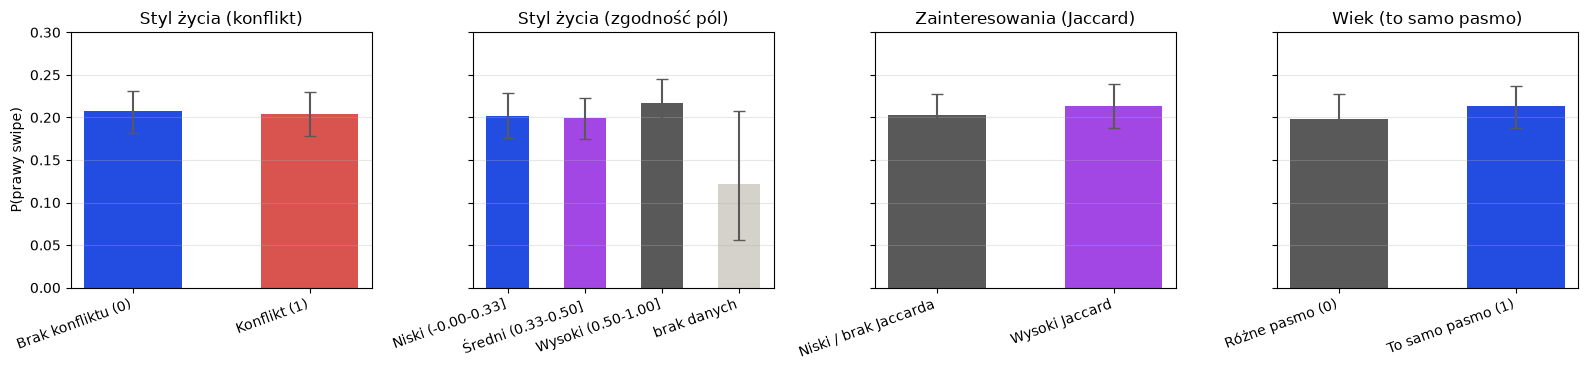

In [5]:
fig, axes = plt.subplots(1, 4, figsize=(16, 3.8), sharey=True)
panels = [
    (axes[0], tbl_conflict, "Styl życia (konflikt)", [BLUE, CORAL]),
    (axes[1], tbl_agree, "Styl życia (zgodność pól)", [BLUE, PURPLE, GRAY, HAIR][: len(tbl_agree)]),
    (axes[2], tbl_jaccard, "Zainteresowania (Jaccard)", [GRAY, PURPLE]),
    (axes[3], tbl_age, "Wiek (to samo pasmo)", [GRAY, BLUE]),
]
for ax, t, title, colors in panels:
    y = t["odsetek_prawych"].to_numpy()
    ax.bar(range(len(t)), y, color=colors, width=0.55)
    ax.errorbar(
        range(len(t)),
        y,
        yerr=[y - t["ci_low_boot"], t["ci_high_boot"] - y],
        fmt="none",
        color=GRAY,
        capsize=4,
        lw=1.5,
    )
    ax.set_xticks(range(len(t)))
    ax.set_xticklabels(
        [k.split(" (")[0] if len(k) > 22 else k for k in t["kategoria"]], rotation=20, ha="right"
    )
    ax.set_title(title)
    ax.set_ylim(0, 0.3)
    ax.grid(axis="y", alpha=0.3)
axes[0].set_ylabel("P(prawy swipe)")
plt.tight_layout()
plt.show()

## 4. Wiek: kierunek, nie podobieństwo (Z3)

`age_band_diff` (odbiorca − nadawca) mówi o **kierunku**; poprzedni wniosek („preferencja podobnego wieku”) mylił go z podobieństwem. Sprawdzamy wprost, czy odbiorca
młodszy o jedno pasmo ma wyższe szanse niż ta sama grupa wiekowa: stawki wewnątrz pasma nadawcy, kontrast z bootstrapu po nadawcach
oraz logit z efektami stałymi pasma nadawcy (SE klastrowane po nadawcy). Pasmo 18-20 nie może mieć młodszych odbiorców, więc nie ma kontrastu.
Komórki z mniej niż 5 nadawcami są tłumione.

In [6]:
age_res = h1_audit.age_direction_check(df, n_boot=N_BOOT, seed=SEED)
print(
    "Odsetek prawych swipe'ów: pasmo nadawcy × różnica pasm (odbiorca − nadawca);"
    " NaN = komórka stłumiona (< 5 nadawców)"
)
display(age_res["cells"].pivot(index="age_band_sender", columns="age_band_diff", values="rate"))
print(
    "Kontrast: P(prawy | odbiorca młodszy o 1 pasmo) − P(prawy | to samo pasmo),"
    " wewnątrz pasma nadawcy (95% CI, bootstrap po nadawcach)"
)
display(age_res["contrast"])
print("Logit z FE pasma nadawcy: OR względem tego samego pasma (95% CI, SE klastrowane po nadawcy)")
display(age_res["pooled"])

Odsetek prawych swipe'ów: pasmo nadawcy × różnica pasm (odbiorca − nadawca); NaN = komórka stłumiona (< 5 nadawców)


age_band_diff,-3,-2,-1,0,1,2,3
age_band_sender,,,,,,,
18-20,NaN,NaN,NaN,0.2051,0.1374,0.0948,0.0657
21-23,NaN,NaN,0.2627,0.2713,0.2049,0.1195,NaN
24-26,NaN,0.3013,0.3131,0.2700,0.1746,NaN,NaN
27+,0.2419,0.2152,0.2362,0.2534,NaN,NaN,NaN


Kontrast: P(prawy | odbiorca młodszy o 1 pasmo) − P(prawy | to samo pasmo), wewnątrz pasma nadawcy (95% CI, bootstrap po nadawcach)


,age_band_sender,n_same,n_younger,n_users,rate_same,rate_younger,diff_younger_minus_same,ci_low,ci_high
0,21-23,3981,12819,310,0.2713,0.2627,-0.0086,-0.0318,0.0136
1,24-26,811,1763,135,0.2700,0.3131,0.0431,0.0042,0.0849
2,27+,801,741,137,0.2534,0.2362,-0.0173,-0.0643,0.0334


Logit z FE pasma nadawcy: OR względem tego samego pasma (95% CI, SE klastrowane po nadawcy)


,term,coef,se,or,ci_low,ci_high,p_value
0,younger_by_2plus,-0.0038,0.1008,0.9963,0.8176,1.2139,0.9703
1,younger_by_1,-0.0275,0.0583,0.9728,0.8677,1.0907,0.6369
2,older_by_1,-0.4765,0.0476,0.6210,0.5656,0.6817,0.0000
3,older_by_2plus,-1.0378,0.0983,0.3542,0.2921,0.4295,0.0000


## 5. Zainteresowania: IDF-Jaccard i baseline losowych par (Z6)

Czy wspólne hobby u prawych swipe'ów to więcej niż przypadek? Baseline: zbiory hobby odbiorców tasowane między swipe'ami **w obrębie równej liczby tagów**
(zachowana liczba tagów i rozkład tagów, zerwana zgodność nadawca–odbiorca). Porównujemy średni Jaccard prawych i lewych swipe'ów z rozkładem z permutacji.
Dla wartości obserwowanych podajemy CI z bootstrapu po nadawcach. **Uwaga:** p z permutacji traktuje swipe'y jako wymienne i nie uwzględnia klastrowania po użytkownikach,
więc jest zbyt optymistyczne; rozstrzyga CI klastrowane. Wariant IDF używa tych samych wag co kolumna `interests_idf_jaccard`.

In [7]:
idf_w, idf_unseen = load_user_idf(DATA_DIR)
# spójność: kolumna datasetu = jaccard ważony wagami z users (próbka)
chk = df.sample(2000, random_state=SEED)
recomputed = [
    weighted_jaccard(s, r, idf_w, idf_unseen)
    for s, r in zip(chk["interests_set_sender"], chk["interests_set_receiver"], strict=True)
]
assert np.allclose(recomputed, chk["interests_idf_jaccard"], atol=1e-6)

perm_plain = h1_audit.interests_permutation_baseline(df, n_perm=N_PERM, seed=SEED)
perm_idf = h1_audit.interests_permutation_baseline(
    df, n_perm=N_PERM, seed=SEED, weights=idf_w, default_weight=idf_unseen
)
for name, res in [("zwykły Jaccard", perm_plain), ("IDF-Jaccard", perm_idf)]:
    print(
        f"--- {name}: prawe vs lewe swipe'y, obserwowane vs permutacje"
        f" (n = {res['n_swipes']:,}) ---"
    )
    display(res["summary"].round(4))
print(
    "p_two_sided = 1/(N_PERM+1) = minimum rozdzielczości testu"
    " przy 500 permutacjach; nie jest to p = 0."
)

--- zwykły Jaccard: prawe vs lewe swipe'y, obserwowane vs permutacje (n = 94,295) ---


,group,observed,obs_ci_low,obs_ci_high,perm_mean,perm_lo,perm_hi,p_two_sided
0,right,0.0694,0.0626,0.0759,0.0652,0.0637,0.0666,NaN
1,left,0.0654,0.0622,0.0685,0.0658,0.0650,0.0665,NaN
2,right_minus_left,0.0040,-0.0021,0.0104,-0.0006,-0.0023,0.0011,0.0020


--- IDF-Jaccard: prawe vs lewe swipe'y, obserwowane vs permutacje (n = 94,295) ---


,group,observed,obs_ci_low,obs_ci_high,perm_mean,perm_lo,perm_hi,p_two_sided
0,right,0.0598,0.0542,0.0651,0.0559,0.0547,0.0572,NaN
1,left,0.0560,0.0532,0.0585,0.0563,0.0556,0.0569,NaN
2,right_minus_left,0.0038,-0.0014,0.0090,-0.0004,-0.0019,0.0012,0.0020


p_two_sided = 1/(N_PERM+1) = minimum rozdzielczości testu przy 500 permutacjach; nie jest to p = 0.


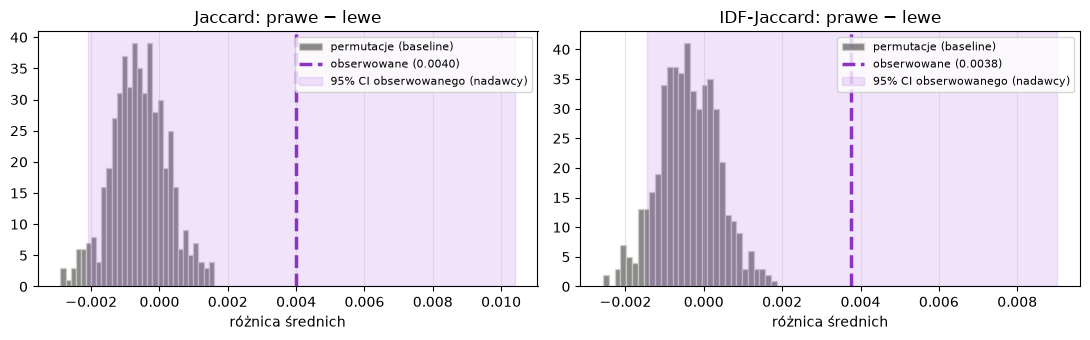

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
for ax, (name, res) in zip(axes, [("Jaccard", perm_plain), ("IDF-Jaccard", perm_idf)], strict=True):
    ax.hist(
        res["perm_diff"],
        bins=30,
        color=GRAY,
        alpha=0.7,
        edgecolor=HAIR,
        label="permutacje (baseline)",
    )
    obs = res["summary"].set_index("group").loc["right_minus_left"]
    ax.axvline(
        obs["observed"],
        color=PURPLE_INK,
        lw=2.5,
        ls="--",
        label=f"obserwowane ({obs['observed']:.4f})",
    )
    ax.axvspan(
        obs["obs_ci_low"],
        obs["obs_ci_high"],
        color=PURPLE,
        alpha=0.15,
        label="95% CI obserwowanego (nadawcy)",
    )
    ax.set_title(f"{name}: prawe − lewe")
    ax.set_xlabel("różnica średnich")
    ax.legend(frameon=True, fontsize=8)
    ax.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

## 6. Główny wynik: trzy bloki, identyczne kontrole (Z1, Z2, Z4)

### 6.1 Odtworzenie liczb sprzed audytu

Specyfikacja `spec_old` (same_sex w bloku wieku, kontrole tylko miasto) musi dać liczby sprzed zmian: ΔLL stylu życia 41,38, ΔLL wieku+zainteresowań 739,14, CV AUC (null 0,500; styl życia 0,519; wiek+zainteresowania 0,581; pełny 0,584).

In [9]:
legacy = h1.fit_h1_logit_models(df, h1.LEGACY_SPEC)
cv_legacy = h1.grouped_cv_h1(df, n_splits=N_FOLDS, seed=SEED, spec=h1.LEGACY_SPEC)
auc_legacy = cv_legacy.groupby("block")["auc"].mean()
repro = pd.DataFrame(
    {
        "wartość sprzed audytu": [92754, 41.38, 739.14, 0.500, 0.519, 0.581, 0.584],
        "odtworzona (spec_old)": [
            legacy["data_len"],
            round(legacy["delta_lifestyle_over_interests_ll"], 2),
            round(legacy["delta_interests_over_lifestyle_ll"], 2),
            round(auc_legacy["null"], 3),
            round(auc_legacy["lifestyle"], 3),
            round(auc_legacy["age_interests"], 3),
            round(auc_legacy["full"], 3),
        ],
    },
    index=[
        "n głównej próby",
        "ΔLL styl życia",
        "ΔLL wiek+zainteresowania",
        "CV AUC null",
        "CV AUC styl życia",
        "CV AUC wiek+zainteresowania",
        "CV AUC pełny",
    ],
)
display(repro)
assert (
    repro["wartość sprzed audytu"].astype(float) - repro["odtworzona (spec_old)"].astype(float)
).abs().max() < 1e-3 + 5e-3
print("OK: liczby sprzed audytu odtworzone.")

,wartość sprzed audytu,odtworzona (spec_old)
n głównej próby,92754.0000,92754.0000
ΔLL styl życia,41.3800,41.3800
ΔLL wiek+zainteresowania,739.1400,739.1400
CV AUC null,0.5000,0.5000
CV AUC styl życia,0.5190,0.5190
CV AUC wiek+zainteresowania,0.5810,0.5810
CV AUC pełny,0.5840,0.5840


OK: liczby sprzed audytu odtworzone.


### 6.2 Model po audycie: te same kontrole we wszystkich modelach

Modele: `controls` (same kontrole), trzy bloki osobno, trzy pary, pełny. Tabela `summary` pokazuje liczbę zmiennych: każdy model zawiera te same kontrole
(Z1; poprzednio `lifestyle` nie miał kontroli płci ani wieku). Współczynniki `sex_<para>` z mniej niż 5 użytkownikami są tłumione.

In [10]:
h1_res = h1.fit_h1_logit_models(df)
print(f"n = {h1_res['data_len']:,}; kontrole w każdym modelu: {h1_res['control_names']}")
display(h1_res["summary"])
counts = h1_audit.sex_pair_user_counts(df)
or_tbl = h1_audit.mask_small_cells(
    h1_res["odds_ratios"][["zmienna", "coef", "se", "or", "ci_low", "ci_high", "p_value"]], counts
)
print("Ilorazy szans w modelu pełnym (SE klastrowane dwustronnie)")
display(or_tbl.round(3))

n = 92,754; kontrole w każdym modelu: ['sex_F_M', 'sex_F_O', 'sex_M_F', 'sex_M_M', 'sex_M_O', 'sex_O_F', 'sex_O_M', 'sex_O_O', 'city_same', 'city_diff']


,model,n_vars,llf,aic,bic,pseudo_r2
0,null,0,-47310.9738,94623.9477,94633.3854,0.0000
1,controls,10,-45511.8815,91045.7631,91149.5778,0.0380
2,age,13,-44973.6609,89975.3217,90107.4496,0.0494
3,interests,13,-45497.4367,91022.8734,91155.0013,0.0383
4,lifestyle,13,-45467.2290,90962.4579,91094.5858,0.0390
5,age_interests,16,-44962.7133,89959.4266,90119.8676,0.0496
6,age_lifestyle,16,-44935.7568,89905.5136,90065.9546,0.0502
7,interests_lifestyle,16,-45450.5071,90935.0142,91095.4552,0.0393
8,full,19,-44922.2571,89884.5141,90073.2683,0.0505


Ilorazy szans w modelu pełnym (SE klastrowane dwustronnie)


,zmienna,coef,se,or,ci_low,ci_high,p_value,suppressed
0,const,-0.9780,0.2290,0.3760,0.2400,0.5890,0.0000,False
1,sex_F_M,-0.8760,0.1290,0.4160,0.3230,0.5360,0.0000,False
2,sex_F_O,-0.7170,0.2070,0.4880,0.3260,0.7320,0.0010,False
3,sex_M_F,0.5070,0.1450,1.6600,1.2500,2.2040,0.0000,False
4,sex_M_M,0.0770,0.1510,1.0800,0.8040,1.4510,0.6070,False
5,sex_M_O,-0.0870,0.2160,0.9170,0.6010,1.3990,0.6860,False
6,sex_O_F,0.8100,0.3730,2.2470,1.0810,4.6710,0.0300,False
7,sex_O_M,1.2690,0.4250,3.5570,1.5450,8.1880,0.0030,False
8,sex_O_O,1.1370,0.5680,3.1160,1.0240,9.4790,0.0450,False
9,city_same,-0.2310,0.1780,0.7940,0.5600,1.1250,0.1940,False


### 6.3 Przyrost każdego z trzech bloków (Z4)

Dla każdego bloku: ΔLL **jako pierwszy** (ponad kontrole), **jako ostatni** (ponad dwa pozostałe) i **średnia po wszystkich 6 kolejnościach** (wartość Shapleya; trzy średnie sumują się do ΔLL pełnego modelu).
Bloki mają po 3 zmienne, ale raportujemy też ΔLL na stopień swobody i ΔAIC (ujemny = blok się opłaca). Wiersz `age+interests` to porównanie z karty (styl życia vs wiek+zainteresowania).

,df,dll_first,dll_first_per_df,daic_first,dll_last,dll_last_per_df,daic_last,dll_mean,dll_mean_per_df,daic_mean
block,,,,,,,,,,
age,3,538.2200,179.4100,-1070.4400,528.2500,176.0800,-1050.5000,533.1900,177.7300,-1060.3800
interests,3,14.4400,4.8100,-22.8900,13.5000,4.5000,-21.0000,13.9300,4.6400,-21.8500
lifestyle,3,44.6500,14.8800,-83.3100,40.4600,13.4900,-74.9100,42.5100,14.1700,-79.0200
age+interests,6,549.1700,91.5300,-1086.3400,544.9700,90.8300,-1077.9400,547.0700,91.1800,-1082.1400


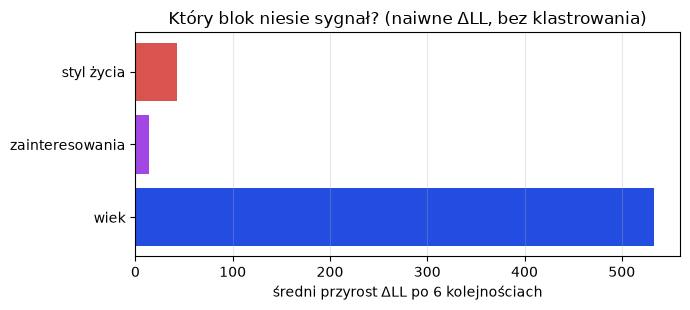

In [11]:
inc = h1_audit.block_increments_from_fit(h1_res)
display(inc.set_index("block").round(2))

fig, ax = plt.subplots(figsize=(7, 3.2))
b3 = inc.set_index("block").loc[["age", "interests", "lifestyle"]]
ax.barh(["wiek", "zainteresowania", "styl życia"], b3["dll_mean"], color=[BLUE, PURPLE, CORAL])
ax.set_xlabel("średni przyrost ΔLL po 6 kolejnościach")
ax.set_title("Który blok niesie sygnał? (naiwne ΔLL, bez klastrowania)")
ax.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

### 6.4 Kryterium z karty: CI różnicy przyrostów (Z5)

Różnica ΔLL(styl życia) − ΔLL(wiek+zainteresowania) oraz − ΔLL(zainteresowania), − ΔLL(wiek). Bootstrap klastrowy (`N_BOOT` = 1000, stałe ziarno):
raz z losowaniem **nadawców**, raz **odbiorców**; kolumny `*_conservative` to szerszy z dwóch przedziałów.
Definicje „pierwszy/ostatni” dają tę samą różnicę dla `age+interests` (algebraicznie: (L−C) − (AI−C) = (F−AI) − (F−L) = L − AI); średnia po kolejnościach jest jej bliska.
Dodatnia różnica = styl życia ma większy przyrost. H1 jest potwierdzona tylko wtedy, gdy różnica jest dodatnia i CI nie obejmuje zera.

In [12]:
block_df = {"age": 3, "interests": 3, "lifestyle": 3}
tabs = {}
for col in ("user_key", "target_user_key"):
    obs_ll, boot_ll = h1_audit.bootstrap_model_loglik(df, cluster_col=col, n_boot=N_BOOT, seed=SEED)
    tabs[col] = h1_audit.summarise_block_differences(obs_ll, boot_ll, block_df)
diff_ci = h1_audit.combine_cluster_cis(tabs["user_key"], tabs["target_user_key"])
display(diff_ci.round(2))

,definition,contrast,estimate,ci_low_sender,ci_high_sender,ci_low_receiver,ci_high_receiver,ci_low_conservative,ci_high_conservative,wider_is,excludes_zero_conservative
0,first,lifestyle - age+interests,-504.5200,-883.4500,-300.7600,-602.1900,-416.0900,-883.4500,-300.7600,sender,True
1,first,lifestyle - interests,30.2100,-63.2700,118.4500,2.9300,58.7400,-63.2700,118.4500,sender,False
2,first,lifestyle - age,-493.5700,-848.6300,-274.4800,-589.7300,-401.6200,-848.6300,-274.4800,sender,True
3,last,lifestyle - age+interests,-504.5200,-883.4500,-300.7600,-602.1900,-416.0900,-883.4500,-300.7600,sender,True
4,last,lifestyle - interests,26.9600,-59.2800,106.3900,2.0000,52.5600,-59.2800,106.3900,sender,False
5,last,lifestyle - age,-487.7900,-845.7600,-273.2600,-583.3800,-396.5000,-845.7600,-273.2600,sender,True
6,mean,lifestyle - age+interests,-504.5600,-883.1200,-300.7500,-602.1300,-416.1500,-883.1200,-300.7500,sender,True
7,mean,lifestyle - interests,28.5800,-62.0400,112.4900,2.7700,55.4700,-62.0400,112.4900,sender,False
8,mean,lifestyle - age,-490.6800,-847.2200,-273.0900,-586.0600,-399.1600,-847.2200,-273.0900,sender,True


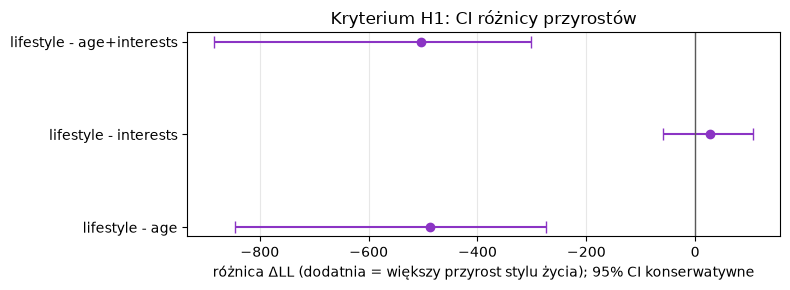

In [13]:
d_last = diff_ci[diff_ci["definition"] == "last"].reset_index(drop=True)
fig, ax = plt.subplots(figsize=(8, 3))
yy = np.arange(len(d_last))[::-1]
ax.errorbar(
    d_last["estimate"],
    yy,
    xerr=[
        d_last["estimate"] - d_last["ci_low_conservative"],
        d_last["ci_high_conservative"] - d_last["estimate"],
    ],
    fmt="o",
    color=PURPLE_INK,
    capsize=4,
)
ax.axvline(0, color=GRAY, lw=1)
ax.set_yticks(yy)
ax.set_yticklabels(d_last["contrast"])
ax.set_xlabel("różnica ΔLL (dodatnia = większy przyrost stylu życia); 95% CI konserwatywne")
ax.set_title("Kryterium H1: CI różnicy przyrostów")
ax.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

### 6.5 Test na przypadek: tasowanie stylu życia odbiorców (shuffled null baseline)

Losowo tasujemy cechy stylu życia między **odbiorcami** (całymi osobami, z zachowaniem liczby swipe'ów i popularności profilu) i porównujemy ΔLL stylu życia
(ponad kontrole, wiek i zainteresowania) z rozkładem z permutacji. Ten test już uwzględnia strukturę odbiorców, w odróżnieniu od ΔLL na poziomie swipe'ów.

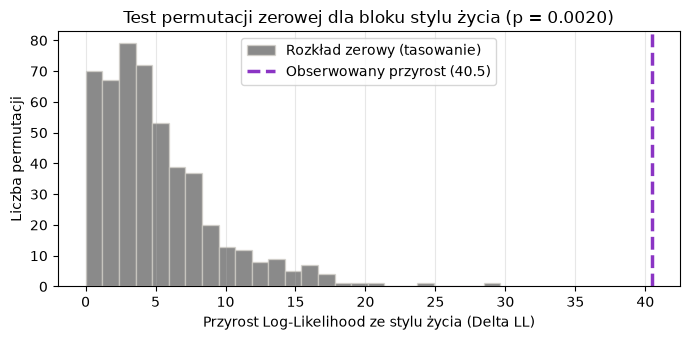

Obserwowany przyrost: 40.46; z tasowania: 5.10 (95%: [0.39, 15.63]); p = 0.0020 (min. rozdzielczość 0.0020)


In [14]:
obs_perm, null_lls, perm_p = h1.permutation_null_lifestyle(df, n_perm=N_PERM, seed=SEED)
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.hist(
    null_lls, bins=25, color=GRAY, alpha=0.7, edgecolor=HAIR, label="Rozkład zerowy (tasowanie)"
)
ax.axvline(
    obs_perm,
    color=PURPLE_INK,
    lw=2.5,
    linestyle="--",
    label=f"Obserwowany przyrost ({obs_perm:.1f})",
)
ax.set_xlabel("Przyrost Log-Likelihood ze stylu życia (Delta LL)")
ax.set_ylabel("Liczba permutacji")
ax.set_title(f"Test permutacji zerowej dla bloku stylu życia (p = {perm_p:.4f})")
ax.legend(frameon=True)
ax.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()
q025, q975 = np.quantile(null_lls, [0.025, 0.975])
print(
    f"Obserwowany przyrost: {obs_perm:.2f}; z tasowania: {null_lls.mean():.2f}"
    f" (95%: [{q025:.2f}, {q975:.2f}]); p = {perm_p:.4f}"
    f" (min. rozdzielczość {1 / (N_PERM + 1):.4f})"
)

## 7. Styl życia per pole (Z7, analiza drugorzędna i eksploracyjna)

Siedem pól strukturalnych (po uzupełnieniu tagami, D13). Dla każdego: status pary (zgodny / niezgodny / jedna strona brak / obie brak; poziomy rzadsze niż 50 swipe'ów łączone z „jedna strona brak”),
łączny test Walda (SE klastrowane dwustronnie), ΔLL pola jako ostatniego i pierwszego, **korekta Holma na 7 testów**.
Palenie osobno kierunkowo: `N` = niepalący, pozostałe kody = użytkownik (założenie bez codebooka). `cleanliness` i `noise_level` mogą być wartościami domyślnymi (P6) i mają prawie wspólne braki
(te same ok. 1% użytkowników), więc ich indywidualne współczynniki „brak danych” są niestabilne; interpretujemy tylko łączne testy.

In [15]:
field_res = h1_audit.per_field_analysis(df)
print(f"n = {field_res['n']:,}")
display(field_res["fields"].round(4))
print("Palenie: kierunek (OR względem zgodnych kodów; SE klastrowane dwustronnie)")
display(field_res["smoking_direction"].round(3))
print(
    "Test symetrii (niepalący→użytkownik = użytkownik→niepalący):"
    f" p = {field_res['smoking_asymmetry_p']:.3f}"
)

n = 92,754


,field,df,dll_last,dll_first,wald_chi2,p_raw,possible_default,p_holm
0,daily_routine,3,2.6774,8.1564,2.6513,0.4486,False,1.0000
1,lifestyle,3,5.9216,24.3789,1.4931,0.6839,False,1.0000
2,work_from_home,3,54.0521,77.9746,4.0263,0.2586,False,1.0000
3,cleanliness,2,5.1770,32.5272,5.0173,0.0814,True,0.5697
4,noise_level,2,3.6382,30.2258,2.9924,0.2240,True,1.0000
5,smoking,3,52.8665,64.6106,4.5159,0.2109,False,1.0000
6,alcohol,3,25.3578,5.0695,1.8449,0.6052,False,1.0000


Palenie: kierunek (OR względem zgodnych kodów; SE klastrowane dwustronnie)


,level,or,ci_low,ci_high,p_value,n
0,both_missing,0.7320,0.5150,1.0380,0.0800,6826
1,nonsmoker_to_user,0.8600,0.7760,0.9530,0.0040,11798
2,one_missing,0.8330,0.6990,0.9930,0.0420,36712
3,user_to_nonsmoker,0.9360,0.6810,1.2860,0.6830,10319
4,user_vs_other_user,1.0420,0.7510,1.4460,0.8050,3155


Test symetrii (niepalący→użytkownik = użytkownik→niepalący): p = 0.646


## 8. Analizy wrażliwości (Z8)

12 scenariuszy; kolumna `status` mówi, czy scenariusz był zaplanowany przed audytem (D6, D7, G6, karta 3.2), czy dodany po nim.
`delta_ll_lifestyle` = ΔLL stylu życia jako ostatniego bloku; `delta_ll_interests` = ΔLL wieku+zainteresowań jako ostatniego bloku (nazwa historyczna);
`delta_ll_age_last` i `delta_ll_hobby_last` rozbijają go na pojedyncze bloki. W scenariuszu `spec_old` blok wieku zawiera `same_sex`.

,scenariusz,status,n_swipe,delta_ll_lifestyle,delta_r2_lifestyle,delta_ll_interests,delta_r2_interests,delta_ll_age_last,delta_ll_hobby_last
0,"main (as-of D7, brak Hyderabadu D10)",pre-rejestrowana,92754,40.4560,0.0010,544.9720,0.0120,528.2500,13.5000
1,tylko prior_version (D7),pre-rejestrowana,86653,28.9520,0.0010,515.5150,0.0120,498.9830,14.3340
2,oba prior_version (D7),pre-rejestrowana,46863,37.2580,0.0020,353.6340,0.0160,339.5460,11.5480
3,bez kont skrajnych (D6),pre-rejestrowana,76151,66.0570,0.0020,582.3570,0.0140,567.3510,11.5220
4,aktywni nadawcy >= 10 (D6),pre-rejestrowana,91102,39.4050,0.0010,539.0320,0.0120,524.5830,11.5500
5,"bez miasta ""inne"" (G6)",pre-rejestrowana,83358,41.5280,0.0010,414.1280,0.0100,397.7570,12.9650
6,"spec_old (same_sex w bloku wieku, bez kontroli...",post hoc (audyt),92754,41.3790,0.0010,739.1440,0.0160,722.5730,12.6550
7,same_sex zamiast sex_pair,post hoc (audyt),92754,36.0670,0.0010,889.9460,0.0190,872.5980,12.7640
8,+ |roznica pasm|^2 (karta 3.2),pre-rejestrowana,92754,40.3930,0.0010,557.6260,0.0120,540.9040,13.0840
9,+ efekty stale pasma nadawcy,post hoc (audyt),92754,38.5040,0.0010,372.6030,0.0080,355.0620,13.8740


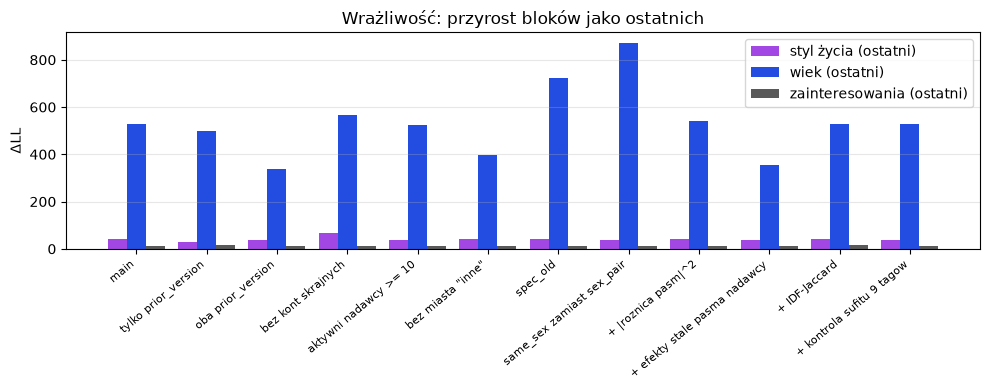

In [16]:
sens_df = h1.sensitivity_analysis_h1(df)
display(sens_df.round(3))

fig, ax = plt.subplots(figsize=(10, 4))
x = np.arange(len(sens_df))
w = 0.27
ax.bar(x - w, sens_df["delta_ll_lifestyle"], w, label="styl życia (ostatni)", color=PURPLE)
ax.bar(x, sens_df["delta_ll_age_last"], w, label="wiek (ostatni)", color=BLUE)
ax.bar(x + w, sens_df["delta_ll_hobby_last"], w, label="zainteresowania (ostatni)", color=GRAY)
ax.set_xticks(x)
ax.set_xticklabels(
    [s.split(" (")[0][:34] for s in sens_df["scenariusz"]], rotation=40, ha="right", fontsize=8
)
ax.set_ylabel("ΔLL")
ax.set_title("Wrażliwość: przyrost bloków jako ostatnich")
ax.legend(frameon=True)
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

## 9. Czy styl życia pomaga u nowych osób? Walidacja krzyżowa po nadawcach (D18, Z5)

5 foldów, każdy nadawca w jednym foldzie. Metryki: logloss, AUC, **AUC-PR** (dodane). Odchylenie między foldami opisuje zmienność uczenia, ale nie przedział różnicy modeli:
dlatego poniżej **sparowane różnice** liczone na predykcjach out-of-fold z bootstrapem po nadawcach (bootstrap jest warunkowy na dopasowanych modelach foldów, bez ponownego uczenia).
Dodatnie wartości = poprawa (dla logloss: spadek straty).

In [17]:
cv_res = h1.grouped_cv_h1(df, n_splits=N_FOLDS, seed=SEED)
keep = ["null", "controls", "age", "interests", "lifestyle", "age_interests", "full"]
cv_summary = cv_res.groupby("block")[["logloss", "auc", "auc_pr"]].agg(["mean", "std"]).loc[keep]
print("Średnie testowe z 5 foldów (± odchylenie między foldami)")
display(cv_summary.round(4))

Średnie testowe z 5 foldów (± odchylenie między foldami)


logloss           auc        auc_pr       
                 mean    std   mean    std   mean    std
block                                                   
null           0.5116 0.0320 0.5000 0.0000 0.2077 0.0238
controls       0.4946 0.0316 0.6160 0.0108 0.2781 0.0347
age            0.4892 0.0326 0.6424 0.0116 0.3091 0.0240
interests      0.4946 0.0317 0.6181 0.0082 0.2800 0.0266
lifestyle      0.4946 0.0319 0.6223 0.0044 0.2788 0.0208
age_interests  0.4893 0.0327 0.6423 0.0126 0.3101 0.0218
full           0.4894 0.0330 0.6432 0.0132 0.3064 0.0187

In [18]:
oof = h1_audit.oof_predictions(df, n_splits=N_FOLDS, seed=SEED)
cv_diff = h1_audit.paired_cv_differences(oof, n_boot=N_BOOT_CV, seed=SEED)
display(cv_diff[cv_diff["definition"] == "last"].round(5).reset_index(drop=True))
print("Definicja 'first' (przyrost ponad same kontrole):")
display(cv_diff[cv_diff["definition"] == "first"].round(5).reset_index(drop=True))

,metric,definition,contrast,estimate,ci_low,ci_high
0,logloss,last,gain: lifestyle,-0.0001,-0.0007,0.0006
1,logloss,last,gain: age+interests,0.0052,0.0021,0.0088
2,logloss,last,gain: interests,-0.0001,-0.0006,0.0004
3,logloss,last,gain: age,0.0052,0.0021,0.0088
4,logloss,last,lifestyle - age+interests,-0.0053,-0.0087,-0.0021
5,logloss,last,lifestyle - interests,0.0000,-0.0007,0.0007
6,logloss,last,lifestyle - age,-0.0053,-0.0088,-0.0020
7,auc,last,gain: lifestyle,0.0017,-0.0008,0.0040
8,auc,last,gain: age+interests,0.0240,0.0144,0.0337
9,auc,last,gain: interests,-0.0003,-0.0023,0.0015


Definicja 'first' (przyrost ponad same kontrole):


,metric,definition,contrast,estimate,ci_low,ci_high
0,logloss,first,gain: lifestyle,-0.0001,-0.0008,0.0006
1,logloss,first,gain: age+interests,0.0052,0.0020,0.0087
2,logloss,first,gain: interests,-0.0001,-0.0006,0.0004
3,logloss,first,gain: age,0.0053,0.0022,0.0088
4,logloss,first,lifestyle - age+interests,-0.0053,-0.0087,-0.0021
5,logloss,first,lifestyle - interests,0.0000,-0.0008,0.0008
6,logloss,first,lifestyle - age,-0.0054,-0.0089,-0.0021
7,auc,first,gain: lifestyle,0.0112,0.0050,0.0180
8,auc,first,gain: age+interests,0.0335,0.0216,0.0455
9,auc,first,gain: interests,0.0036,-0.0018,0.0088


## 10. Walidacja instrumentu: normalizacja tagów (Z9)

W repo **nie ma** raportu zgodności normalizacji tagów (agent AI vs człowiek, κ Cohena): `docs/codebook.md` (część D) opisuje plan walidacji
(zbiór wzorcowy z 3 adnotatorami, κ agent–wzorzec z 90% CI), ale bez wyników; skrypt zgodności na gałęzi `feat/gold-set` dotyczy etykiet bio (H3), nie tagów.
Nie podajemy więc żadnej wartości κ. Jedyna liczba dostępna w repo to zgodność dwóch **propozycji agentów** (Claude vs Gemini) co do kategorii kanonicznych tagów, co **nie jest** walidacją względem człowieka.
Lista rzeczy do zrobienia: `docs/h1/open-questions.md`, sekcja „Walidacja instrumentu AI”.

In [19]:
prop = pd.read_csv("../docs/tag_category_proposal.csv")
n_tags = len(prop)
n_agree = int((prop["proposed_category_claude"] == prop["proposed_category_gemini"]).sum())
print(
    f"Propozycje kategorii Claude vs Gemini: zgodne dla {n_agree} z {n_tags} tagów"
    f" ({n_agree / n_tags:.1%}); to NIE jest walidacja względem zbioru wzorcowego człowieka."
)

Propozycje kategorii Claude vs Gemini: zgodne dla 58 z 68 tagów (85.3%); to NIE jest walidacja względem zbioru wzorcowego człowieka.


## 11. Wniosek

Liczby w nawiasach odsyłają do **tablicy dowodów E1–E11** poniżej (każde twierdzenie ma tam liczbę z przedziałem lub p). Badamy **prawy swipe w aplikacji**, nie faktyczny najem (D1, G9); wyniki opisują związki w obserwowanej ekspozycji (G1), bez interpretacji przyczynowej.

### Werdykt: H1 nie została potwierdzona

Kryterium z karty wymaga, by przyrost po dodaniu stylu życia był **większy** niż po dodaniu wieku i zainteresowań, z CI różnicy bez zera. Jest odwrotnie: ΔΔLL (styl życia − wiek+zainteresowania) = −504,5, konserwatywne 95% CI [−883,4; −300,8] (szerszy był bootstrap po nadawcach; E3). To samo wychodzi dla każdej definicji przyrostu (pierwszy / ostatni / średnia po kolejnościach) i **poza próbą**: w CV po nadawcach sparowane różnice przyrostów (styl życia − wiek+zainteresowania) są ujemne dla logloss (−0,0053 [−0,0087; −0,0021]), AUC (−0,0224 [−0,0330; −0,0117]) i AUC-PR (−0,0310 [−0,0499; −0,0164]) (E4). We wszystkich 12 scenariuszach wrażliwości ΔLL stylu życia (29–66) jest wielokrotnie mniejsze niż ΔLL wieku+zainteresowań (354–890; E11, sekcja 8; to naiwne ΔLL bez osobnych CI).

### Co niesie sygnał

1. **Wiek, nie zainteresowania.** Średni ΔLL po 6 kolejnościach: wiek 533,2, styl życia 42,5, zainteresowania 13,9 (E2). Różnica styl życia − wiek: −487,8 [−845,8; −273,3] (E3). Poprzednie sformułowanie „dominują wiek i zainteresowania” było więc w praktyce „dominuje wiek”: zainteresowania dają najmniej (dLL/df 4,6 wobec 14,2 dla stylu życia).
2. **Styl życia vs zainteresowania: nierozstrzygnięte.** Różnica ΔLL = +27,0 [−59,3; 106,4] (E3) i brak rozstrzygnięcia w CV po logloss i AUC-PR. Jedyny wynik na korzyść stylu życia to AUC jako blok *pierwszy* (+0,0075 [0,0013; 0,0139], sekcja 9); znika dla logloss, AUC-PR i dla bloku ostatniego, więc nie traktujemy go jako wsparcia dla H1.
3. **Styl życia: słaby sygnał, bez mierzalnego zysku poza próbą.** Blok jest powyżej przypadku w teście tasowania odbiorców (ΔLL 40,5 wobec 5,1 [0,4; 15,6] z permutacji; p na poziomie minimum rozdzielczości 1/501, sekcja 6.5), ale jako ostatni blok nie poprawia CV: AUC +0,0017 [−0,0008; 0,0040], logloss −0,0000 [−0,0007; 0,0006] (E5). Żadne z 7 pól nie przechodzi korekty Holma (najmniejsze p po Holmie 0,57, `cleanliness`; E8), a naiwne ΔLL (np. 54 dla `work_from_home`) przy teście Walda ze SE klastrowanymi daje p = 0,26, czyli ΔLL na poziomie swipe'a zawyża dowód. Palenie: niepalący → użytkownik OR 0,86 [0,78; 0,95], ale asymetrii kierunkowej nie wykazano (p = 0,65; E9; analiza eksploracyjna).
4. **Wiek to kierunek, nie podobieństwo.** Przy efektach stałych pasma nadawcy odbiorca młodszy o jedno pasmo ma OR 0,97 [0,87; 1,09] względem tej samej grupy, starszy o jedno pasmo 0,62 [0,57; 0,68], starszy o dwa lub więcej 0,35 [0,29; 0,43] (E6). To wzorzec „kary za starszego odbiorcę”, a nie „preferencji podobnego wieku”; po uwzględnieniu odległości i kierunku sama zgodność pasma (`same_band`) nie jest istotna (OR 0,78 [0,56; 1,07], sekcja 6.2). Wcześniejszy wniosek 1 czytał znak różnicy jako podobieństwo i jest wycofany.
5. **Zainteresowania.** Prawe swipe'y mają wyższy średni Jaccard (0,0694) niż losowe pary o tej samej liczbie tagów (0,0652 [0,0637; 0,0666]), a lewe leżą na poziomie przypadku. Różnica prawe − lewe 0,0040 [−0,0021; 0,0104] ma jednak CI klastrowane po nadawcach obejmujące zero (IDF-Jaccard: 0,0038 [−0,0014; 0,0090]; E7). Zgodność z permutacją na poziomie swipe'a (p minimalne) jest zbyt optymistyczna, bo nie uwzględnia klastrowania.

### Zastrzeżenia

- **Rozdzielczość pomiaru.** Pola stylu życia mają 74–81% braków na poziomie profili (G14; dotyczy 5 z 7 pól). Na poziomie par odsetek swipe'ów z brakiem u którejkolwiek strony to 47–92% dla tych pól (E10), a `cleanliness` i `noise_level` (ok. 2%) mogą być wartościami domyślnymi (P6), co sztucznie zawyża ich „zgodność”. Wiek jest kompletny, ale gruby (4 pasma). Porównanie bloków zależy więc od jakości pomiaru, nie tylko od realnego związku: słaby przyrost stylu życia nie dowodzi, że styl życia nie ma znaczenia, a jedynie że **ten pomiar** niewiele dodaje.
- **Widoczność cech (hipoteza niezweryfikowana).** Możliwe, że wiek jest dla użytkowników bardziej widoczny niż pola stylu życia i to tłumaczy wzorzec. Dane tego nie rozstrzygają: nie zawierają zdjęć (G5), a widoczność pól i tagów na karcie to pytanie do dostawcy (karta 2.2, pyt. 2 i 4). Brak efektu nie oznacza braku wpływu, jeśli cecha nie była widoczna.
- **Próba i ekspozycja.** Próbę głównej analizy stanowi 92 754 swipe'ów (1525 nadawców, 1354 odbiorców; E1); feed może zawężać wariancję zmiennych (G1); 65% wyświetlanych profili to pasmo 18-20 (G13); wąska, studencka próba (G6).
- **Specyfikacja zmieniona po obejrzeniu wyników.** Audyt poprawił kontrole (`sex_pair`) i specyfikację wieku po pierwszym uruchomieniu. Dlatego nawet analiza „konfirmacyjna” ma stopnie swobody badacza; raportujemy wszystkie warianty (`spec_old`, `same_sex`, 12 scenariuszy), a wniosek o braku potwierdzenia jest ten sam w każdym.

### Co jest konfirmacyjne, a co eksploracyjne

| Analiza | Status | Uwaga |
|---|---|---|
| Kryterium H1: CI różnicy przyrostów ΔLL, obie kolejności, bootstrap po nadawcach i odbiorcach | **konfirmacyjna** (kryterium z karty 4, H1; D16) | implementacja i specyfikacja kontroli poprawione po audycie (post hoc) |
| CV po użytkownikach: logloss, AUC, AUC-PR, sparowane różnice | **konfirmacyjna** (karta 3.3; D18) | CI warunkowe na dopasowanych modelach foldów |
| Test tasowania stylu życia odbiorców | konfirmacyjna (null baseline z zasad kursu) | |
| Scenariusze D6, D7, G6; `|Δ|²`; IDF-Jaccard; baseline losowych par | pre-rejestrowana wrażliwość (A6, karta 3.2, 4) | |
| `sex_pair` zamiast `same_sex`; `spec_old`; efekty stałe pasma nadawcy; kontrola sufitu 9 tagów | **post hoc (audyt)** | wszystkie raportowane |
| Rozkład na 3 bloki (Shapley), ΔLL/df, ΔAIC | **eksploracyjna / post hoc (audyt)** | |
| Kierunek wieku (młodszy/starszy odbiorca) | **eksploracyjna / post hoc (audyt)** | |
| Analiza per pole, kierunek palenia, Holm | **eksploracyjna** (drugorzędna, D16) | Holm tylko na 7 testów pól |

### Tablica dowodów

In [20]:
# Tablica dowodów: każdy wniosek z sekcji 11 ma tu odpowiadającą mu liczbę z przedziałem lub p.
def ci(lo, hi, nd=2):
    return f"[{lo:.{nd}f}; {hi:.{nd}f}]"


def get(tbl, **kw):
    m = np.ones(len(tbl), bool)
    for k, v in kw.items():
        m &= (tbl[k] == v).to_numpy()
    return tbl[m].iloc[0]


inc_i = inc.set_index("block")


def r_last(c):
    return get(diff_ci, definition="last", contrast=c)


def cvl(metric, c, d="last"):
    return get(cv_diff, metric=metric, definition=d, contrast=c)


pooled = age_res["pooled"].set_index("term")
fields = field_res["fields"].set_index("field")
smk = field_res["smoking_direction"].set_index("level")
ps = perm_plain["summary"].set_index("group")
sens_idx = sens_df.set_index("scenariusz")

rows = []


def add(eid, claim, value, interval, note=""):
    rows.append(
        {"id": eid, "twierdzenie": claim, "liczba": value, "CI / p": interval, "uwaga": note}
    )


add(
    "E1",
    "Próba główna H1",
    f"{h1_res['data_len']:,} swipe'ów",
    "",
    f"{int(funnel.iloc[-1]['senders'])} nadawców, {int(funnel.iloc[-1]['receivers'])} odbiorców",
)
for b, lab in [("age", "wiek"), ("interests", "zainteresowania"), ("lifestyle", "styl życia")]:
    add(
        "E2",
        f"Średni ΔLL bloku: {lab}",
        f"{inc_i.loc[b, 'dll_mean']:.1f}",
        "",
        f"dLL/df {inc_i.loc[b, 'dll_mean_per_df']:.1f}; naiwne (bez klastrowania)",
    )
for c in ["lifestyle - age+interests", "lifestyle - age", "lifestyle - interests"]:
    r = r_last(c)
    add(
        "E3",
        f"ΔΔLL (ostatni): {c}",
        f"{r['estimate']:.1f}",
        ci(r["ci_low_conservative"], r["ci_high_conservative"], 1),
        f"szerszy: {r['wider_is']}; wyklucza 0: {bool(r['excludes_zero_conservative'])}",
    )
for metric in ["logloss", "auc", "auc_pr"]:
    r = cvl(metric, "lifestyle - age+interests")
    add(
        "E4",
        f"CV, różnica przyrostów (ostatni), {metric}: styl życia − wiek+zainteresowania",
        f"{r['estimate']:.4f}",
        ci(r["ci_low"], r["ci_high"], 4),
        "dodatnia = styl życia lepszy",
    )
for metric in ["logloss", "auc", "auc_pr"]:
    r = cvl(metric, "gain: lifestyle")
    add(
        "E5",
        f"CV, przyrost stylu życia jako ostatniego bloku, {metric}",
        f"{r['estimate']:.4f}",
        ci(r["ci_low"], r["ci_high"], 4),
        "dodatnia = poprawa",
    )
for t in ["younger_by_1", "older_by_1", "older_by_2plus"]:
    add(
        "E6",
        f"Wiek, OR względem tego samego pasma: {t}",
        f"{pooled.loc[t, 'or']:.2f}",
        ci(pooled.loc[t, "ci_low"], pooled.loc[t, "ci_high"]),
        "FE pasma nadawcy; SE po nadawcy",
    )
r = ps.loc["right_minus_left"]
add(
    "E7",
    "Hobby: Jaccard prawych − lewych (obserwowane)",
    f"{r['observed']:.4f}",
    ci(r["obs_ci_low"], r["obs_ci_high"], 4),
    f"baseline permutacji: {r['perm_mean']:.4f} {ci(r['perm_lo'], r['perm_hi'], 4)};"
    f" CI klastrowane obejmuje 0: {bool(r['obs_ci_low'] <= 0 <= r['obs_ci_high'])}",
)
r = perm_idf["summary"].set_index("group").loc["right_minus_left"]
add(
    "E7",
    "Hobby (IDF-Jaccard): prawe − lewe",
    f"{r['observed']:.4f}",
    ci(r["obs_ci_low"], r["obs_ci_high"], 4),
    f"baseline: {r['perm_mean']:.4f}",
)
add(
    "E8",
    "Styl życia per pole: najmniejsze p po Holmie",
    f"{fields['p_holm'].min():.3f}",
    "",
    f"pole: {fields['p_holm'].idxmin()};"
    f" liczba pól z p_holm < 0.05: {(fields['p_holm'] < 0.05).sum()} z 7",
)
r = smk.loc["nonsmoker_to_user"]
add(
    "E9",
    "Palenie: niepalący → użytkownik, OR",
    f"{r['or']:.2f}",
    ci(r["ci_low"], r["ci_high"]),
    f"test symetrii p = {field_res['smoking_asymmetry_p']:.2f}",
)
miss = {
    f: float((df[f"lsf_{f}"].isin(["one_missing", "both_missing"])).mean())
    for f in [
        "daily_routine",
        "lifestyle",
        "work_from_home",
        "smoking",
        "alcohol",
        "cleanliness",
        "noise_level",
    ]
}
add(
    "E10",
    "Rozdzielczość pomiaru: udział swipe'ów z brakiem pola u którejkolwiek strony"
    " (min–max po polach)",
    f"{min(miss.values()):.0%}–{max(miss.values()):.0%}",
    "",
    "; ".join(f"{k} {v:.0%}" for k, v in miss.items()),
)
sc = sens_idx["delta_ll_lifestyle"]
add(
    "E11",
    "Wrażliwość: zakres ΔLL stylu życia (ostatni) po 12 scenariuszach",
    f"{sc.min():.1f}–{sc.max():.1f}",
    "",
    "zakres ΔLL wieku+zainteresowań:"
    f" {sens_idx['delta_ll_interests'].min():.0f}–{sens_idx['delta_ll_interests'].max():.0f}",
)

evidence = pd.DataFrame(rows)
pd.set_option("display.max_colwidth", 140)
display(evidence)

,id,twierdzenie,liczba,CI / p,uwaga
0,E1,Próba główna H1,"92,754 swipe'ów",,"1525 nadawców, 1354 odbiorców"
1,E2,Średni ΔLL bloku: wiek,533.2,,dLL/df 177.7; naiwne (bez klastrowania)
2,E2,Średni ΔLL bloku: zainteresowania,13.9,,dLL/df 4.6; naiwne (bez klastrowania)
3,E2,Średni ΔLL bloku: styl życia,42.5,,dLL/df 14.2; naiwne (bez klastrowania)
4,E3,ΔΔLL (ostatni): lifestyle - age+interests,-504.5,[-883.4; -300.8],szerszy: sender; wyklucza 0: True
5,E3,ΔΔLL (ostatni): lifestyle - age,-487.8,[-845.8; -273.3],szerszy: sender; wyklucza 0: True
6,E3,ΔΔLL (ostatni): lifestyle - interests,27.0,[-59.3; 106.4],szerszy: sender; wyklucza 0: False
7,E4,"CV, różnica przyrostów (ostatni), logloss: styl życia − wiek+zainteresowania",-0.0053,[-0.0087; -0.0021],dodatnia = styl życia lepszy
8,E4,"CV, różnica przyrostów (ostatni), auc: styl życia − wiek+zainteresowania",-0.0224,[-0.0330; -0.0117],dodatnia = styl życia lepszy
9,E4,"CV, różnica przyrostów (ostatni), auc_pr: styl życia − wiek+zainteresowania",-0.0310,[-0.0499; -0.0164],dodatnia = styl życia lepszy
